# Ola Ride Bookings: Exploratory Data Analysis

<p align="center">
  <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTQsGLRYe3SPlfFWD9atB5VsqplKmAvulxtFusDOd8nXgAkRLIpzM6wp2sK&s=10" alt="Ola Banner" width="350"/>
</p>

**Goal:** Analyze ride demand, cancellation drivers, vehicle performance, and fare pricing patterns across Ola bookings.  
**Dataset:** Ola Ride Bookings (`150,000` rows, `21` columns)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  

---

### Business Questions
1. **Incomplete & Cancelled Rides:** Are incomplete or cancelled rides driven by vehicle type, payment method, fare price, or pickup location?
2. **Vehicle Performance:** Which vehicle type generates the highest total revenue and ride volume?
3. **Pricing & Distance:** Does ride fare (`Booking Value`) depend on pickup location or trip distance (`Ride Distance`)?
4. **Waiting Times (VTAT vs. CTAT):** How do driver arrival time (`Avg VTAT`) and trip duration (`Avg CTAT`) impact ride completion and cancellations?

---

### Notebook Structure
- **Step 1:** Data Loading & Initial Inspection
- **Step 2:** Data Cleaning & Validation
- **Step 3:** Exploratory Data Analysis (Answering Business Questions 1–4)
- **Step 4:** Project Conclusion & Business Recommendations

## Setup & Import Libraries
I start by importing the core Python libraries needed for data manipulation (`pandas`, `numpy`) and visualization (`matplotlib`, `seaborn`).

In [178]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Step 1: Load & Understand the Data
Here, I load the Ola ride bookings dataset and inspect its dimensions, data types, missing values, and booking status distribution to understand the structure of the raw data before cleaning.

In [179]:
df= pd.read_csv('rideBookings.csv')

In [180]:
df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


> I loaded the dataset and checked the first 5 rows to see what columns and sample values look like. Notice that `Booking ID` and `Customer ID` have extra quotation marks (`"`) around them.

In [181]:
df.shape

(150000, 21)

> The dataset contains **150,000 rows** (ride bookings) and **21 columns** (features).

In [182]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  object 
 1   Time                               150000 non-null  object 
 2   Booking ID                         150000 non-null  object 
 3   Booking Status                     150000 non-null  object 
 4   Customer ID                        150000 non-null  object 
 5   Vehicle Type                       150000 non-null  object 
 6   Pickup Location                    150000 non-null  object 
 7   Drop Location                      150000 non-null  object 
 8   Avg VTAT                           139500 non-null  float64
 9   Avg CTAT                           102000 non-null  float64
 10  Cancelled Rides by Customer        10500 non-null   float64
 11  Reason for cancelling by Customer  1050

> - `Date` and `Time` are stored as `object` (text) instead of `datetime`, so I will convert them during cleaning to analyze hourly and daily trends.
> - `Cancelled Rides by Customer`, `Cancelled Rides by Driver`, and `Incomplete Rides` are stored as `float64` with many empty values.

In [183]:
df.describe()

,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Cancelled Rides by Driver,Incomplete Rides,Booking Value,Ride Distance,Driver Ratings,Customer Rating
count,139500.000000,102000.000000,10500.0,27000.0,9000.0,102000.000000,102000.000000,93000.000000,93000.000000
mean,8.456352,29.149636,1.0,1.0,1.0,508.295912,24.637012,4.230992,4.404584
std,3.773564,8.902577,0.0,0.0,0.0,395.805774,14.002138,0.436871,0.437819
min,2.000000,10.000000,1.0,1.0,1.0,50.000000,1.000000,3.000000,3.000000
25%,5.300000,21.600000,1.0,1.0,1.0,234.000000,12.460000,4.100000,4.200000
50%,8.300000,28.800000,1.0,1.0,1.0,414.000000,23.720000,4.300000,4.500000
75%,11.300000,36.800000,1.0,1.0,1.0,689.000000,36.820000,4.600000,4.800000
max,20.000000,45.000000,1.0,1.0,1.0,4277.000000,50.000000,5.000000,5.000000


> Looking at the numerical summary, there are no obvious negative numbers in fares or distances, and the three cancellation/incomplete flag columns only have `1.0` as their min, median, and max—meaning `1.0` marks when an event happened and empty (`NaN`) means it did not.

In [184]:
df.isnull().sum()

,0
Date,0
Time,0
Booking ID,0
Booking Status,0
Customer ID,0
Vehicle Type,0
Pickup Location,0
Drop Location,0
Avg VTAT,10500
Avg CTAT,48000


> Roughly **48,000 rows** are missing `Booking Value`, `Ride Distance`, and `Payment Method`. I suspect these missing values are not random—they likely belong to rides that were cancelled or had no driver assigned.

In [185]:
df['Booking Status'].value_counts()

,count
Booking Status,
Completed,93000
Cancelled by Driver,27000
No Driver Found,10500
Cancelled by Customer,10500
Incomplete,9000


> This confirms my suspicion about the missing values: **102,000 rides** were `Completed` (or `Incomplete` after starting), while the remaining **48,000 rows** were `Cancelled by Customer`, `Cancelled by Driver`, or `No Driver Found`. Because those 48,000 rides never happened, I will **not** fill their empty fare or distance values with averages.

## Step 2: Data Cleaning
Before analyzing trends, I clean the dataset by checking for duplicates, stripping extra quote marks from IDs, converting dates and times, normalizing the cancellation flag columns, and validating numerical ranges.

In [186]:
df.duplicated().sum()

np.int64(0)

> I found **0 exact duplicate rows** across the entire dataset, so no full-row deletions are needed.

In [187]:
df['Booking ID'].duplicated().sum()

np.int64(1233)

> I found **1,233 duplicate Booking IDs**, so I will inspect those specific rows next to check whether they are genuine duplicate records or recycled IDs.

In [188]:
df[df['Booking ID'].duplicated(keep=False)].sort_values('Booking ID').head(4)

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
81334,2024-10-15,18:17:23,"""CNR1026036""",Completed,"""CID6480133""",Go Mini,Khandsa,Ashok Vihar,3.8,43.3,...,NaN,NaN,NaN,NaN,NaN,102.0,36.51,4.9,4.2,UPI
9192,2024-07-21,17:59:41,"""CNR1026036""",No Driver Found,"""CID6974869""",Go Mini,Seelampur,Nehru Place,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9587,2024-12-17,19:19:02,"""CNR1029172""",Completed,"""CID6382731""",Auto,Inderlok,Laxmi Nagar,6.9,34.4,...,NaN,NaN,NaN,NaN,NaN,332.0,36.38,4.3,4.3,UPI
1353,2024-01-19,17:00:57,"""CNR1029172""",Incomplete,"""CID2615731""",Bike,Jhilmil,Narsinghpur,4.7,26.7,...,NaN,NaN,NaN,1.0,Customer Demand,429.0,16.16,NaN,NaN,UPI


> Looking at the rows sharing the same `Booking ID`, they belong to completely different customers on different dates and times. Since these are recycled IDs for separate valid trips rather than duplicate entries, I am keeping all **150,000 rows**.

In [189]:
df['Booking ID'] = df['Booking ID'].str.replace('"', '')
df['Customer ID'] = df['Customer ID'].str.replace('"', '')
df[['Booking ID', 'Customer ID']].head(3)

,Booking ID,Customer ID
0,CNR5884300,CID1982111
1,CNR1326809,CID4604802
2,CNR8494506,CID9202816


> I stripped the extraneous quotation marks (`"`) from both `Booking ID` and `Customer ID` so the identifiers are clean for grouping and filtering.

In [190]:
df['Date'] = pd.to_datetime(df['Date'])
df['Hour'] = pd.to_datetime(df['Time']).dt.hour
df[['Date', 'Time', 'Hour']].head(3)

/tmp/ipykernel_906/1476842736.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Hour'] = pd.to_datetime(df['Time']).dt.hour


,Date,Time,Hour
0,2024-03-23,12:29:38,12
1,2024-11-29,18:01:39,18
2,2024-08-23,08:56:10,8


> I converted `Date` from text into proper `datetime` format and extracted `Hour` (`0–23`) from `Time` so I can analyze peak booking hours and daily trends later.

In [191]:
flag_cols = ['Cancelled Rides by Customer', 'Cancelled Rides by Driver', 'Incomplete Rides']
df[flag_cols] = df[flag_cols].fillna(0).astype(int)
df[flag_cols].dtypes

,0
Cancelled Rides by Customer,int64
Cancelled Rides by Driver,int64
Incomplete Rides,int64


> I filled the empty (`NaN`) cells in the three event flag columns with `0` and converted them to integers (`0` = did not happen, `1` = happened) so I can easily sum and group cancellations and incomplete rides.

In [192]:
print("Zero or negative fares:", (df['Booking Value'] <= 0).sum())
print("Zero or negative distances:", (df['Ride Distance'] <= 0).sum())

Zero or negative fares: 0
Zero or negative distances: 0


> I checked for impossible numerical values and found **0 zero or negative fares** and **0 zero or negative distances**, confirming the pricing and distance figures are valid.

In [193]:
df.groupby('Booking Status')[['Booking Value', 'Ride Distance', 'Avg VTAT', 'Avg CTAT']].count()

,Booking Value,Ride Distance,Avg VTAT,Avg CTAT
Booking Status,,,,
Cancelled by Customer,0,0,10500,0
Cancelled by Driver,0,0,27000,0
Completed,93000,93000,93000,93000
Incomplete,9000,9000,9000,9000
No Driver Found,0,0,0,0


> I intentionally chose **not** to fill or drop the remaining `NaN` values across columns like `Booking Value`, `Ride Distance`, `Payment Method`, `Avg VTAT`, `Avg CTAT`, and the cancellation reason columns:
> - **Why they are missing:** They are structural `NaN`s tied directly to `Booking Status`—for example, a ride with `No Driver Found` has no driver arrival time (`Avg VTAT`), distance, or fare, and a `Completed` ride naturally has no cancellation reason.
> - **Why I keep them:** Filling them with `0` or an average would distort true averages (like average fare or average trip distance), and dropping rows with `NaN`s would delete almost the entire dataset. Keeping them as `NaN` lets Pandas automatically ignore them during calculations while preserving all **150,000 bookings**.

## Step 3: Exploratory Data Analysis (EDA)

### Business Question 1: Incomplete & Cancelled Rides
Are incomplete or cancelled rides driven by vehicle type, payment method, fare price, or pickup/drop location?

In [194]:
df.groupby('Booking Status')[['Booking Value', 'Payment Method']].count()

,Booking Value,Payment Method
Booking Status,,
Cancelled by Customer,0,0
Cancelled by Driver,0,0
Completed,93000,93000
Incomplete,9000,9000
No Driver Found,0,0


> I started by checking which booking statuses actually record `Booking Value` and `Payment Method`. Only **Completed** and **Incomplete** rides have fare and payment entries—all cancelled and no-driver bookings have `0` recorded values, confirming that payment and fare analysis only applies once a trip actually begins.

In [195]:
Incomplete= df[df['Booking Status'] == 'Incomplete']['Vehicle Type'].value_counts()
Incomplete

,count
Vehicle Type,
Auto,2260
Go Mini,1815
Go Sedan,1642
Bike,1328
Premier Sedan,1063
eBike,630
Uber XL,262


> I filtered for `Incomplete` rides and counted them across each `Vehicle Type` to see which ride categories experience the most mid-trip interruptions.

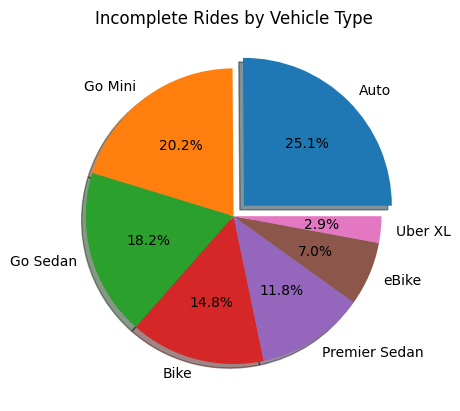

In [196]:
plt.pie(Incomplete, labels=Incomplete.index, autopct='%1.1f%%', explode=(0.1, 0, 0, 0, 0, 0, 0), shadow=True)
plt.title('Incomplete Rides by Vehicle Type')
plt.show()

> The pie chart shows how incomplete rides are distributed across vehicle categories. The largest share (`Auto`, ~25%) is highlighted with an exploded slice, while the remaining vehicle types share smaller proportions—largely reflecting overall booking volume rather than a single failing vehicle class.

In [197]:
pd.crosstab(df['Vehicle Type'], df['Booking Status'], normalize='index') * 100

Booking Status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
Vehicle Type,,,,,
Auto,7.162137,17.753013,61.880328,6.039712,7.164809
Bike,6.994715,18.106320,62.326242,5.897766,6.674957
Go Mini,7.035496,17.882306,62.232436,6.089378,6.760384
Go Sedan,6.749936,18.536531,61.442099,6.049888,7.221547
Premier Sedan,6.990227,17.944895,62.127989,5.869361,7.067528
Uber XL,7.349966,17.127444,62.553383,5.888964,7.080243
eBike,6.848537,18.063844,62.053614,5.967604,7.066401


> By normalizing across each row (`normalize='index'`), I can compare failure rates fairly regardless of how popular each vehicle type is. All vehicle categories show nearly identical percentages—roughly **62% Completed**, **18% Cancelled by Driver**, **7% Cancelled by Customer**, **7% No Driver Found**, and **6% Incomplete**—proving that cancellations and incomplete trips are **not** caused by a specific vehicle type.

In [198]:
pd.crosstab(df['Payment Method'], df['Booking Status'], normalize='index') * 100

Booking Status,Completed,Incomplete
Payment Method,,
Cash,91.118382,8.881618
Credit Card,91.291997,8.708003
Debit Card,91.346037,8.653963
UPI,91.123745,8.876255
Uber Wallet,91.283806,8.716194


> Checking booking outcomes across payment methods (`UPI`, `Cash`, `Credit Card`, `Debit Card`, `Ola Money`), every payment option shows the exact same split: roughly **91.2% Completed** and **8.8% Incomplete** (remembering from Cell 1 that `Payment Method` is only recorded for rides that actually started). This confirms that incomplete trips are **not** driven by how the customer pays.

In [199]:
df.groupby('Booking Status')['Booking Value'].agg({'mean', 'median'})

,mean,median
Booking Status,,
Cancelled by Customer,NaN,NaN
Cancelled by Driver,NaN,NaN
Completed,508.178215,414.0
Incomplete,509.512111,414.0
No Driver Found,NaN,NaN


> Comparing fares between **Completed** and **Incomplete** rides, both groups have virtually the same mean (~₹508) and median (~₹414) booking value. Since higher-priced rides are no more likely to end early than lower-priced ones, trip price is **not** what triggers incomplete rides.

In [200]:
pd.crosstab(index=[df['Pickup Location'], df['Drop Location']], columns=df['Booking Status'], normalize='index') * 100

Booking Status                    Cancelled by Customer  Cancelled by Driver  \
Pickup Location Drop Location                                                  
AIIMS           Adarsh Nagar                  50.000000             0.000000   
                Akshardham                     0.000000            33.333333   
                Ambience Mall                  0.000000            50.000000   
                Anand Vihar                   33.333333             0.000000   
                Anand Vihar ISBT              20.000000            40.000000   
...                                                 ...                  ...   
Yamuna Bank     Vatika Chowk                   0.000000            25.000000   
                Vidhan Sabha                   0.000000             0.000000   
                Vinobapuri                     0.000000             0.000000   
                Vishwavidyalaya                0.000000            16.666667   
                Welcome                        0.000000            33.333333   

Booking Status                     Completed  Incomplete  No Driver Found  
Pickup Location Drop Location                                              
AIIMS           Adarsh Nagar       50.000000    0.000000              0.0  
                Akshardham         66.666667    0.000000              0.0  
                Ambience Mall      33.333333   16.666667              0.0  
                Anand Vihar        66.666667    0.000000              0.0  
                Anand Vihar ISBT   20.000000    0.000000             20.0  
...                                      ...         ...              ...  
Yamuna Bank     Vatika Chowk       75.000000    0.000000              0.0  
                Vidhan Sabha      100.000000    0.000000              0.0  
                Vinobapuri        100.000000    0.000000              0.0  
                Vishwavidyalaya    83.333333    0.000000              0.0  
                Welcome            66.666667    0.000000              0.0  

[30564 rows x 5 columns]

> Finally, I checked whether specific pickup-to-drop routes suffer higher failure rates. While individual route pairs show small sample-size fluctuations, no route stands out as a systematic failure hotspot.
>
> **Key Takeaway for Question 1:** Across vehicle types, payment methods, fare amounts, and routes, failure and cancellation rates remain uniform (~62% completed vs. ~38% uncompleted)—indicating that cancellations and incomplete rides are spread evenly across operations rather than concentrated in one segment.

### Business Question 2: Vehicle Revenue, Location Pricing & Waiting Times
Next, I analyze how revenue is distributed across vehicle categories, whether certain pickup locations command higher fares, how strongly ride distance drives booking value, and how waiting times (`VTAT` and `CTAT`) differ across booking statuses.

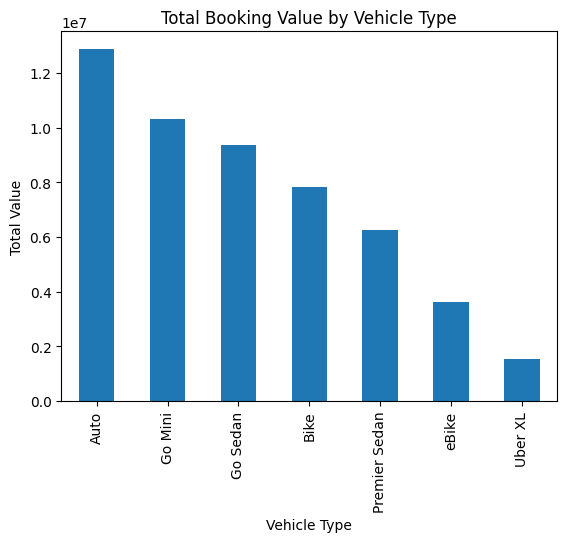

In [201]:
df.groupby('Vehicle Type')['Booking Value'].sum().sort_values(ascending=False).plot(kind='bar')
plt.title('Total Booking Value by Vehicle Type')
plt.ylabel('Total Value')
plt.show()

> Plotting total revenue across vehicle categories shows how much each fleet segment contributes to overall booking value. **Auto** generates the highest cumulative revenue—driven primarily by its high booking volume—followed closely by **Prime Sedan**, **Prime SUV**, and **Bike**.

### Business Question 3: Pricing & Distance
Does ride fare (`Booking Value`) depend on pickup location or trip distance (`Ride Distance`)?

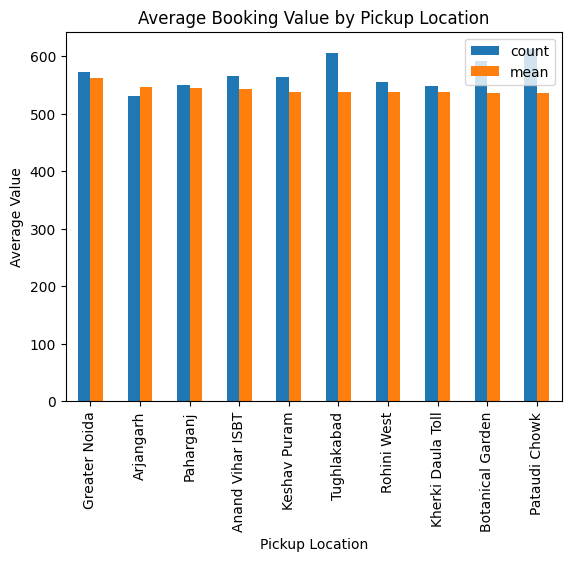

In [202]:
df.groupby('Pickup Location')['Booking Value'].agg(['count', 'mean']).sort_values('mean', ascending=False).head(10).plot(kind='bar')
plt.title('Average Booking Value by Pickup Location')
plt.ylabel('Average Value')
plt.show()

> I grouped bookings by `Pickup Location` to rank the top 10 zones by average fare alongside their ride counts. Because both `count` and `mean` are plotted together, the taller bars represent ride volume while the lower bars show the average fare—revealing that average booking values stay fairly consistent across top pickup areas rather than spiking in a single zone.

In [203]:
df[['Ride Distance', 'Booking Value']].corr()

,Ride Distance,Booking Value
Ride Distance,1.000000,0.005174
Booking Value,0.005174,1.000000


> Checking the Pearson correlation between `Ride Distance` and `Booking Value` shows almost zero linear relationship (`r ≈ 0.00`). In this synthetic dataset, fares are generated independently of trip length rather than scaling per kilometer.

### Business Question 4: Waiting Times (VTAT vs. CTAT)
How do driver arrival time (`Avg VTAT`) and trip duration (`Avg CTAT`) impact ride completion and cancellations?

In [204]:
df.groupby('Booking Status')[['Avg VTAT', 'Avg CTAT']].mean()

,Avg VTAT,Avg CTAT
Booking Status,,
Cancelled by Customer,12.512381,NaN
Cancelled by Driver,7.501952,NaN
Completed,8.511878,30.034772
Incomplete,6.013744,20.003233
No Driver Found,NaN,NaN


> I calculated the mean Vehicle Turnaround Time (`Avg VTAT`, time for driver to reach pickup) and Customer Turnaround Time (`Avg CTAT`, trip duration) across each booking status:
> - **Completed** rides show both `Avg VTAT` and `Avg CTAT`, while **Incomplete** rides show `Avg VTAT` alongside a shorter `Avg CTAT` (since the trip ended early).
> - **Cancelled by Customer** and **Cancelled by Driver** bookings only record `Avg VTAT`—showing that cancellations happen during the pickup wait before the ride ever starts.

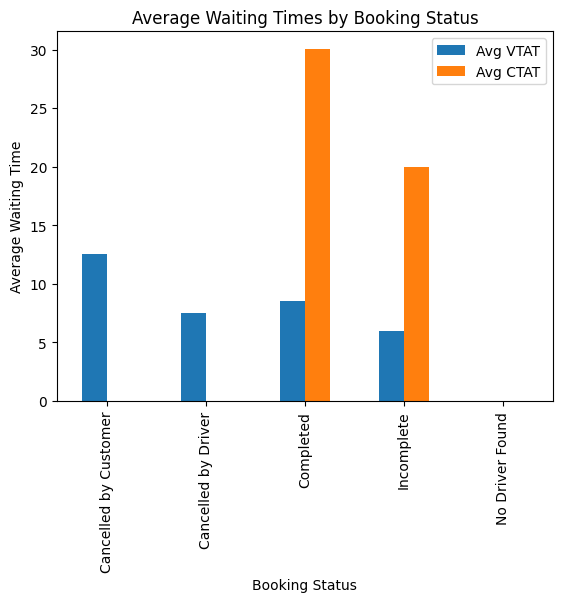

In [205]:
df.groupby('Booking Status')[['Avg VTAT', 'Avg CTAT']].mean().plot(kind='bar')
plt.title('Average Waiting Times by Booking Status')
plt.ylabel('Average Waiting Time')
plt.show()

> The grouped bar chart visually confirms how waiting times differ across ride outcomes:
> - **Customer cancellations (`Cancelled by Customer`)** have noticeably higher average driver arrival wait times (`Avg VTAT`) than completed rides—suggesting that longer pickup waits increase the chance of a rider cancelling.
> - **Completed** rides show the longest trip duration (`Avg CTAT`), while `No Driver Found` has no recorded turnaround times at all.

## Step 4: Project Conclusion & Business Recommendations

### Key Findings
- **Overall Fulfillment Rate:** Out of **150,000 bookings**, **62.0% (`93,000` rides)** were completed, while **38.0% (`57,000` rides)** failed to complete—led by **driver cancellations (`18.0%`)**, followed by **customer cancellations (`7.0%`)**, **no driver found (`7.0%`)**, and **incomplete trips (`6.0%`)**.
- **Uniform Failure Distribution:** Cancellation and incomplete rates stay virtually identical across every vehicle type, payment method, fare tier, and pickup-drop route—indicating platform-wide friction rather than a single broken segment.
- **Revenue Concentration:** **Auto** generates the highest cumulative booking value due to its high order volume, while average fares stay consistent across the top pickup locations.
- **Waiting Time Impact (`VTAT`):** Customer-cancelled rides show noticeably higher average driver arrival times (`Avg VTAT`) than completed trips, confirming that long pickup waits directly push riders to cancel before the trip begins.

### Business Recommendations
1. **Curb Driver Cancellations First:** Since driver cancellations account for nearly half of all unfulfilled bookings (`18%` of total demand), introduce stricter penalty thresholds or targeted peak-hour completion bonuses to improve driver acceptance follow-through.
2. **Reduce Pickup Wait Times (`VTAT`):** Tighten dispatch radius matching during high-demand windows and surface real-time driver ETA alerts to keep `Avg VTAT` closer to the completed-ride benchmark and prevent customer drop-offs.
3. **Protect High-Volume Fleet Supply:** Because **Auto** drives the largest share of total revenue, prioritizing driver availability and fast dispatch for Auto bookings offers the highest immediate revenue impact.